In [1]:

from pathlib import Path
import sys

# Locate the project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Load Hillstrom dataset using the project's shared loader
from src.data_processing.load_data import load_hillstrom_data

df = load_hillstrom_data()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (64000, 12)

First 5 rows:


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [2]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nTreatment group counts:")
print(df["segment"].value_counts())

print("\nOutcome summary:")
display(df[["visit", "conversion", "spend"]].describe())


Dataset shape: (64000, 12)

Column names:
['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend']

Missing values in each column:
recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

Treatment group counts:


segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

Outcome summary:


,visit,conversion,spend
count,64000.000000,64000.000000,64000.000000
mean,0.146781,0.009031,1.050908
std,0.353890,0.094604,15.036448
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000
max,1.000000,1.000000,499.000000


In [3]:

group_results = df.groupby("segment").agg(
    customers=("segment", "size"),
    visit_rate=("visit", "mean"),
    conversion_rate=("conversion", "mean"),
    average_spend=("spend", "mean")
).reset_index()

group_results["visit_rate"] *= 100
group_results["conversion_rate"] *= 100

group_results = group_results.round(3)

display(group_results)


,segment,customers,visit_rate,conversion_rate,average_spend
0,Mens E-Mail,21307,18.276,1.253,1.423
1,No E-Mail,21306,10.617,0.573,0.653
2,Womens E-Mail,21387,15.140,0.884,1.077


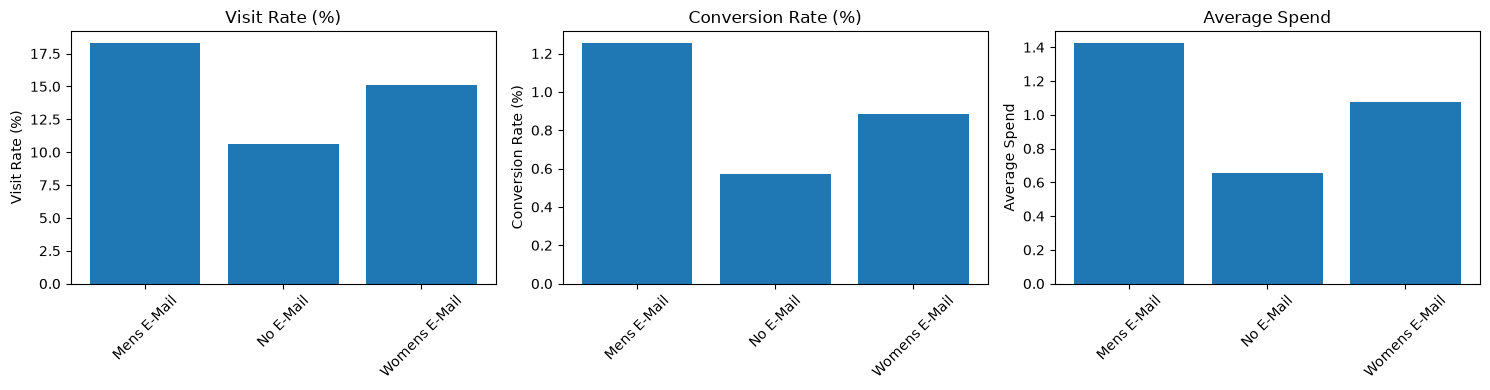

In [4]:

import matplotlib.pyplot as plt

metrics = ["visit_rate", "conversion_rate", "average_spend"]
titles = ["Visit Rate (%)", "Conversion Rate (%)", "Average Spend"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metric, title in zip(axes, metrics, titles):
    ax.bar(group_results["segment"], group_results[metric])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel(title)

plt.tight_layout()
plt.show()


In [5]:

# Compare average customer characteristics across treatment groups

customer_features = [
    "recency",
    "history",
    "mens",
    "womens",
    "newbie"
]

display(
    df.groupby("segment")[customer_features]
      .mean()
      .round(3)
)


,recency,history,mens,womens,newbie
segment,,,,,
Mens E-Mail,5.774,242.836,0.551,0.551,0.502
No E-Mail,5.750,240.883,0.553,0.548,0.502
Womens E-Mail,5.768,242.537,0.549,0.550,0.503


In [6]:

control_rate = df.loc[
    df["segment"] == "No E-Mail", "conversion"
].mean()

treatment_rates = df.groupby("segment")["conversion"].mean()

for group in ["Mens E-Mail", "Womens E-Mail"]:
    treatment_rate = treatment_rates[group]

    difference = (treatment_rate - control_rate) * 100

    print(f"{group}:")
    print(f"  Conversion rate: {treatment_rate * 100:.3f}%")
    print(f"  Difference vs control: {difference:+.3f} percentage points")
    print()


Mens E-Mail:
  Conversion rate: 1.253%
  Difference vs control: +0.681 percentage points

Womens E-Mail:
  Conversion rate: 0.884%
  Difference vs control: +0.311 percentage points



In [7]:

from statsmodels.stats.proportion import proportions_ztest

control = df[df["segment"] == "No E-Mail"]
mens_email = df[df["segment"] == "Mens E-Mail"]
womens_email = df[df["segment"] == "Womens E-Mail"]

comparisons = [
    ("Mens E-Mail", mens_email),
    ("Womens E-Mail", womens_email)
]

for name, treatment in comparisons:
    successes = [
        treatment["conversion"].sum(),
        control["conversion"].sum()
    ]

    sample_sizes = [
        len(treatment),
        len(control)
    ]

    z_stat, p_value = proportions_ztest(
        count=successes,
        nobs=sample_sizes
    )

    print(name)
    print(f"Z-statistic: {z_stat:.3f}")
    print(f"P-value: {p_value:.6f}")
    print("Statistically significant at 5%:",
          p_value < 0.05)
    print()


Mens E-Mail
Z-statistic: 7.385
P-value: 0.000000
Statistically significant at 5%: True

Womens E-Mail
Z-statistic: 3.780
P-value: 0.000157
Statistically significant at 5%: True



In [8]:

from statsmodels.stats.proportion import confint_proportions_2indep

control = df[df["segment"] == "No E-Mail"]

for name in ["Mens E-Mail", "Womens E-Mail"]:
    treatment = df[df["segment"] == name]

    treatment_successes = int(treatment["conversion"].sum())
    treatment_n = len(treatment)

    control_successes = int(control["conversion"].sum())
    control_n = len(control)

    difference = (
        treatment_successes / treatment_n
        - control_successes / control_n
    )

    lower, upper = confint_proportions_2indep(
        treatment_successes,
        treatment_n,
        control_successes,
        control_n,
        method="newcomb"
    )

    print(name)
    print(f"Conversion difference: {difference * 100:.3f} percentage points")
    print(
        f"95% confidence interval: "
        f"[{lower * 100:.3f}, {upper * 100:.3f}] percentage points"
    )
    print()


Mens E-Mail
Conversion difference: 0.681 percentage points
95% confidence interval: [0.501, 0.864] percentage points

Womens E-Mail
Conversion difference: 0.311 percentage points
95% confidence interval: [0.150, 0.475] percentage points



In [9]:

# Keep only Men's Email and No Email customers
model_df = df[
    df["segment"].isin(["Mens E-Mail", "No E-Mail"])
].copy()

# Create the treatment indicator
# 1 = received Men's Email
# 0 = received No Email
model_df["treatment"] = (
    model_df["segment"] == "Mens E-Mail"
).astype(int)

print("Modelling dataset shape:", model_df.shape)

print("\nTreatment group counts:")
print(model_df["treatment"].value_counts())

print("\nFirst 5 rows:")
display(model_df.head())


Modelling dataset shape: (42613, 13)

Treatment group counts:
treatment
1    21307
0    21306
Name: count, dtype: int64

First 5 rows:


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,treatment
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0,0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0,1
8,9,5) $500 - $750,675.07,1,1,Rural,1,Phone,Mens E-Mail,0,0,0.0,1
13,2,2) $100 - $200,101.64,0,1,Urban,0,Web,Mens E-Mail,1,0,0.0,1
14,4,3) $200 - $350,241.42,0,1,Rural,1,Multichannel,No E-Mail,0,0,0.0,0


In [10]:

# Customer characteristics known before the campaign
feature_cols = [
    "recency",
    "history",
    "mens",
    "womens",
    "newbie",
    "history_segment",
    "zip_code",
    "channel"
]

X = model_df[feature_cols]
treatment = model_df["treatment"]
y = model_df["conversion"]

print("Feature matrix shape:", X.shape)
print("Treatment shape:", treatment.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())


Feature matrix shape: (42613, 8)
Treatment shape: (42613,)
Target shape: (42613,)

Feature columns:
['recency', 'history', 'mens', 'womens', 'newbie', 'history_segment', 'zip_code', 'channel']

Target distribution:
conversion
0    42224
1      389
Name: count, dtype: int64


In [11]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Separate numeric and categorical features
numeric_features = [
    "recency", "history", "mens", "womens", "newbie"
]

categorical_features = [
    "history_segment", "zip_code", "channel"
]

# Preprocess numeric and categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_features),
        ("categorical", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

# Split customer rows into training and testing sets
X_train, X_test, y_train, y_test, t_train, t_test = train_test_split(
    X, y, treatment,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training conversions:", int(y_train.sum()))
print("Testing conversions:", int(y_test.sum()))


Training rows: 34090
Testing rows: 8523
Training conversions: 311
Testing conversions: 78


In [12]:

# Create the conversion prediction pipeline
conversion_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using the training data
conversion_model.fit(X_train, y_train)

# Predict conversion probabilities on unseen test data
y_prob = conversion_model.predict_proba(X_test)[:, 1]

# Evaluate ranking performance
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Average Precision (PR-AUC): {pr_auc:.4f}")


ROC-AUC: 0.5495
Average Precision (PR-AUC): 0.0103


In [13]:

# Compare conversion rates in the training data
train_results = model_df.loc[X_train.index].groupby("treatment")["conversion"].agg(
    customers="count",
    conversions="sum",
    conversion_rate="mean"
)

train_results["conversion_rate_percent"] = (
    train_results["conversion_rate"] * 100
)

print(train_results)


           customers  conversions  conversion_rate  conversion_rate_percent
treatment                                                                  
0              17074          101         0.005915                 0.591543
1              17016          210         0.012341                 1.234133


In [14]:

from statsmodels.stats.proportion import confint_proportions_2indep
from scipy.stats import norm

# Separate the two experimental groups
men_group = model_df[model_df["treatment"] == 1]["conversion"]
control_group = model_df[model_df["treatment"] == 0]["conversion"]

n_t = len(men_group)
n_c = len(control_group)

conversions_t = int(men_group.sum())
conversions_c = int(control_group.sum())

rate_t = men_group.mean()
rate_c = control_group.mean()

# Average treatment effect: difference in conversion probabilities
ate = rate_t - rate_c

# 95% confidence interval for the difference in proportions
ci_low, ci_high = confint_proportions_2indep(
    conversions_t, n_t,
    conversions_c, n_c,
    method="newcomb"
)

print(f"Treatment conversion rate: {rate_t * 100:.3f}%")
print(f"Control conversion rate:   {rate_c * 100:.3f}%")
print(f"ATE:                       {ate * 100:.3f} percentage points")
print(
    f"95% confidence interval:   "
    f"[{ci_low * 100:.3f}, {ci_high * 100:.3f}] percentage points"
)


Treatment conversion rate: 1.253%
Control conversion rate:   0.573%
ATE:                       0.681 percentage points
95% confidence interval:   [0.501, 0.864] percentage points


In [15]:

# Step 9G: Fit separate conversion models for treatment and control

# Split training data by experimental assignment
X_train_t = X_train.loc[t_train == 1]
y_train_t = y_train.loc[t_train == 1]

X_train_c = X_train.loc[t_train == 0]
y_train_c = y_train.loc[t_train == 0]

# Use the same preprocessing pipeline for both models
treatment_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

control_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=43,
        n_jobs=-1
    ))
])

# Train each model only on its assigned group
treatment_model.fit(X_train_t, y_train_t)
control_model.fit(X_train_c, y_train_c)

print("Treatment model trained on", len(X_train_t), "customers")
print("Control model trained on", len(X_train_c), "customers")


Treatment model trained on 17016 customers
Control model trained on 17074 customers


In [16]:

# Predict each test customer's conversion probability
# if assigned to Men's Email and if assigned to No Email

prob_if_email = treatment_model.predict_proba(X_test)[:, 1]
prob_if_no_email = control_model.predict_proba(X_test)[:, 1]

# Estimated conditional treatment effect for each customer
individual_effect = prob_if_email - prob_if_no_email

# Store the results
uplift_results = X_test.copy()
uplift_results["actual_treatment"] = t_test
uplift_results["actual_conversion"] = y_test
uplift_results["prob_if_email"] = prob_if_email
uplift_results["prob_if_no_email"] = prob_if_no_email
uplift_results["estimated_uplift"] = individual_effect

print("Test customers:", len(uplift_results))
print("\nEstimated uplift summary:")
print(uplift_results["estimated_uplift"].describe())

print("\nFirst 5 estimated effects:")
display(
    uplift_results[
        ["prob_if_email", "prob_if_no_email", "estimated_uplift"]
    ].head()
)


Test customers: 8523

Estimated uplift summary:
count    8523.000000
mean        0.093754
std         0.217197
min        -0.717846
25%        -0.021987
50%         0.104053
75%         0.236747
max         0.741266
Name: estimated_uplift, dtype: float64

First 5 estimated effects:


,prob_if_email,prob_if_no_email,estimated_uplift
8114,0.274623,0.085458,0.189165
40745,0.559132,0.308441,0.250691
49778,0.322834,0.088911,0.233923
34005,0.437415,0.651094,-0.213679
12383,0.351715,0.466287,-0.114572


In [17]:

# Compare the T-learner's predictions with observed conversion rates
# in the held-out test experiment

test_results = model_df.loc[X_test.index].copy()

test_rate_email = test_results.loc[
    test_results["treatment"] == 1, "conversion"
].mean()

test_rate_control = test_results.loc[
    test_results["treatment"] == 0, "conversion"
].mean()

observed_test_difference = test_rate_email - test_rate_control
predicted_test_uplift = uplift_results["estimated_uplift"].mean()

print(f"Observed test email conversion rate: {test_rate_email * 100:.3f}%")
print(f"Observed test control conversion rate: {test_rate_control * 100:.3f}%")
print(
    f"Observed test difference: "
    f"{observed_test_difference * 100:.3f} percentage points"
)
print(
    f"Mean predicted uplift: "
    f"{predicted_test_uplift * 100:.3f} percentage points"
)



Observed test email conversion rate: 1.328%
Observed test control conversion rate: 0.496%
Observed test difference: 0.832 percentage points
Mean predicted uplift: 9.375 percentage points


In [18]:

# Compare predicted and observed conversion probabilities by group

print("TREATMENT GROUP — MEN'S EMAIL")
print(f"Observed conversion rate: {y_test[t_test == 1].mean() * 100:.3f}%")
print(f"Mean predicted probability: {prob_if_email[t_test == 1].mean() * 100:.3f}%")

print("\nCONTROL GROUP — NO EMAIL")
print(f"Observed conversion rate: {y_test[t_test == 0].mean() * 100:.3f}%")
print(f"Mean predicted probability: {prob_if_no_email[t_test == 0].mean() * 100:.3f}%")


TREATMENT GROUP — MEN'S EMAIL
Observed conversion rate: 1.328%
Mean predicted probability: 30.794%

CONTROL GROUP — NO EMAIL
Observed conversion rate: 0.496%
Mean predicted probability: 21.802%


In [19]:

# Retrain treatment and control models without class weighting

treatment_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=20,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

control_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=20,
        class_weight=None,
        random_state=43,
        n_jobs=-1
    ))
])

treatment_model.fit(X_train_t, y_train_t)
control_model.fit(X_train_c, y_train_c)

# Recalculate test probabilities
prob_if_email = treatment_model.predict_proba(X_test)[:, 1]
prob_if_no_email = control_model.predict_proba(X_test)[:, 1]

# Recalculate estimated uplift
individual_effect = prob_if_email - prob_if_no_email

print("TREATMENT GROUP — MEN'S EMAIL")
print(f"Observed conversion rate: {y_test[t_test == 1].mean() * 100:.3f}%")
print(f"Mean predicted probability: {prob_if_email[t_test == 1].mean() * 100:.3f}%")

print("\nCONTROL GROUP — NO EMAIL")
print(f"Observed conversion rate: {y_test[t_test == 0].mean() * 100:.3f}%")
print(f"Mean predicted probability: {prob_if_no_email[t_test == 0].mean() * 100:.3f}%")

print(f"\nMean predicted uplift: {individual_effect.mean() * 100:.3f} percentage points")


TREATMENT GROUP — MEN'S EMAIL
Observed conversion rate: 1.328%
Mean predicted probability: 1.197%

CONTROL GROUP — NO EMAIL
Observed conversion rate: 0.496%
Mean predicted probability: 0.590%

Mean predicted uplift: 0.632 percentage points


In [20]:

# Update test-customer uplift estimates using the corrected models

uplift_results = X_test.copy()
uplift_results["actual_treatment"] = t_test
uplift_results["actual_conversion"] = y_test
uplift_results["prob_if_email"] = prob_if_email
uplift_results["prob_if_no_email"] = prob_if_no_email
uplift_results["estimated_uplift"] = (
    prob_if_email - prob_if_no_email
)

print("Updated estimated uplift summary:")
print(uplift_results["estimated_uplift"].describe())

print("\nEstimated uplift in percentage points:")
print(
    (uplift_results["estimated_uplift"] * 100)
    .describe()
    .round(3)
)

print("\nFirst 5 updated estimates:")
display(
    uplift_results[
        ["prob_if_email", "prob_if_no_email", "estimated_uplift"]
    ].head()
)


Updated estimated uplift summary:
count    8523.000000
mean        0.006323
std         0.010441
min        -0.045596
25%         0.000808
50%         0.004844
75%         0.011503
max         0.062419
Name: estimated_uplift, dtype: float64

Estimated uplift in percentage points:
count    8523.000
mean        0.632
std         1.044
min        -4.560
25%         0.081
50%         0.484
75%         1.150
max         6.242
Name: estimated_uplift, dtype: float64

First 5 updated estimates:


,prob_if_email,prob_if_no_email,estimated_uplift
8114,0.010154,0.005265,0.004889
40745,0.020289,0.007120,0.013170
49778,0.016573,0.002786,0.013787
34005,0.018950,0.017481,0.001469
12383,0.015958,0.015404,0.000554


In [21]:

# Group test customers into five bands by predicted uplift
import pandas as pd
uplift_results["uplift_group"] = pd.qcut(
    uplift_results["estimated_uplift"],
    q=5,
    labels=["Q1 Lowest", "Q2", "Q3", "Q4", "Q5 Highest"],
    duplicates="drop"
)

# Compare actual conversion rates within each group
uplift_validation = uplift_results.groupby(
    "uplift_group", observed=True
).apply(
    lambda g: pd.Series({
        "customers": len(g),
        "email_customers": int((g["actual_treatment"] == 1).sum()),
        "control_customers": int((g["actual_treatment"] == 0).sum()),
        "email_conversion_rate": g.loc[
            g["actual_treatment"] == 1, "actual_conversion"
        ].mean(),
        "control_conversion_rate": g.loc[
            g["actual_treatment"] == 0, "actual_conversion"
        ].mean(),
        "observed_uplift": (
            g.loc[g["actual_treatment"] == 1, "actual_conversion"].mean()
            - g.loc[g["actual_treatment"] == 0, "actual_conversion"].mean()
        )
    })
)

uplift_validation["observed_uplift_pp"] = (
    uplift_validation["observed_uplift"] * 100
)

display(uplift_validation.round(4))


,customers,email_customers,control_customers,email_conversion_rate,control_conversion_rate,observed_uplift,observed_uplift_pp
uplift_group,,,,,,,
Q1 Lowest,1705.0,877.0,828.0,0.0137,0.0012,0.0125,1.2475
Q2,1704.0,862.0,842.0,0.0081,0.0059,0.0022,0.2182
Q3,1705.0,897.0,808.0,0.0145,0.0062,0.0083,0.8305
Q4,1704.0,870.0,834.0,0.0149,0.0096,0.0054,0.5350
Q5 Highest,1705.0,785.0,920.0,0.0153,0.0022,0.0131,1.3113


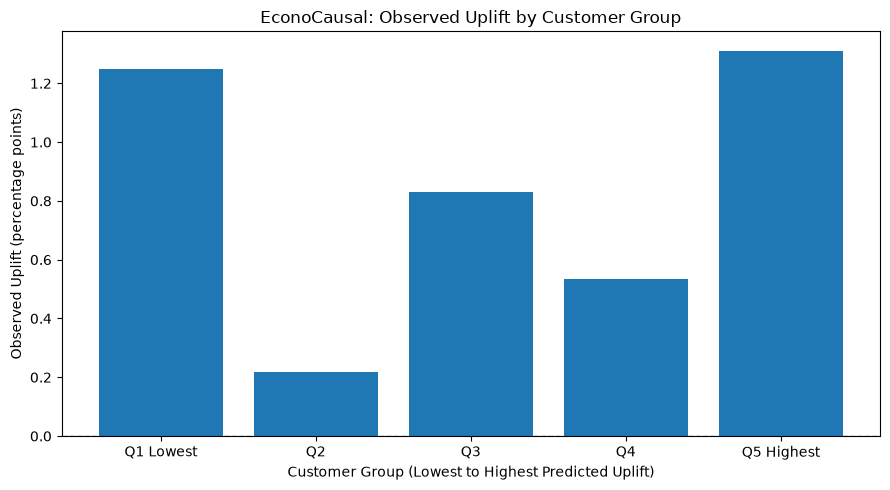

In [22]:

import matplotlib.pyplot as plt

# Get the observed uplift for each predicted-uplift group
groups = uplift_validation.index.astype(str)
uplift_values = uplift_validation["observed_uplift_pp"]

plt.figure(figsize=(9, 5))
plt.bar(groups, uplift_values)

plt.axhline(y=0, linestyle="--", linewidth=1)
plt.xlabel("Customer Group (Lowest to Highest Predicted Uplift)")
plt.ylabel("Observed Uplift (percentage points)")
plt.title("EconoCausal: Observed Uplift by Customer Group")
plt.tight_layout()
plt.show()


In [23]:
import numpy as np
import pandas as pd

# Rank customers by predicted uplift
ranked = uplift_results.sort_values(
    "estimated_uplift", ascending=False
).copy()

# Identify treatment and control groups
is_treatment = (ranked["actual_treatment"] == 1).astype(int)
is_control = (ranked["actual_treatment"] == 0).astype(int)

# Cumulative group counts
ranked["cum_treat_n"] = is_treatment.cumsum()
ranked["cum_control_n"] = is_control.cumsum()

# Cumulative conversions
ranked["cum_treat_y"] = (
    ranked["actual_conversion"] * is_treatment
).cumsum()

ranked["cum_control_y"] = (
    ranked["actual_conversion"] * is_control
).cumsum()

n_t = int(is_treatment.sum())
n_c = int(is_control.sum())

if n_t == 0 or n_c == 0:
    raise ValueError("Both treatment and control groups are required.")

# Fraction of customers targeted
ranked["target_fraction"] = (
    np.arange(1, len(ranked) + 1) / len(ranked)
)

# Cumulative incremental conversions
control_adjustment = np.divide(
    ranked["cum_control_y"] * ranked["cum_treat_n"],
    ranked["cum_control_n"],
    out=np.zeros(len(ranked), dtype=float),
    where=ranked["cum_control_n"].to_numpy() > 0
)

ranked["uplift_curve"] = (
    ranked["cum_treat_y"] - control_adjustment
)

# Random-targeting baseline
total_incremental = (
    ranked["cum_treat_y"].iloc[-1]
    - ranked["cum_control_y"].iloc[-1] * n_t / n_c
)

ranked["random_baseline"] = (
    ranked["target_fraction"] * total_incremental
)

# Include the origin (0 customers targeted, 0 incremental conversions)
x = np.concatenate(([0.0], ranked["target_fraction"].to_numpy()))
curve = np.concatenate(([0.0], ranked["uplift_curve"].to_numpy()))
baseline = np.concatenate(([0.0], ranked["random_baseline"].to_numpy()))

# Qini area above the random-targeting baseline
qini = np.trapezoid(curve - baseline, x)

print(f"Qini coefficient: {qini:.4f}")
print(f"Total incremental conversions estimate: {total_incremental:.3f}")

Qini coefficient: 0.8665
Total incremental conversions estimate: 35.707


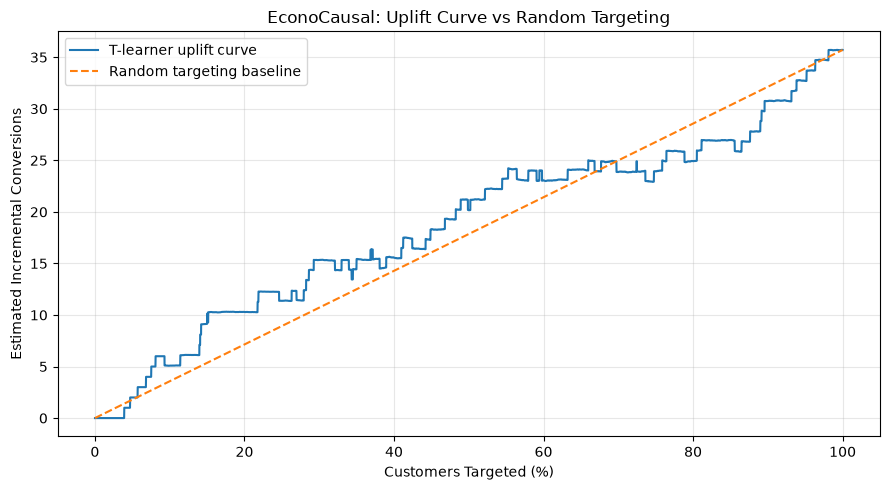

In [24]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    ranked["target_fraction"] * 100,
    ranked["uplift_curve"],
    label="T-learner uplift curve"
)

plt.plot(
    ranked["target_fraction"] * 100,
    ranked["random_baseline"],
    linestyle="--",
    label="Random targeting baseline"
)

plt.xlabel("Customers Targeted (%)")
plt.ylabel("Estimated Incremental Conversions")
plt.title("EconoCausal: Uplift Curve vs Random Targeting")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [25]:

# EconoCausal — Initial Email Campaign Analysis Summary

print("=" * 55)
print("ECONOCAUSAL: EMAIL CAMPAIGN ANALYSIS")
print("=" * 55)

print("\nDATASET")
print(f"Total customers analysed: {len(df):,}")
print("Experiment: Men's Email vs No Email")

print("\nAVERAGE TREATMENT EFFECT")
print(f"Men's Email conversion rate: {rate_t * 100:.3f}%")
print(f"No Email conversion rate:    {rate_c * 100:.3f}%")
print(f"Estimated ATE:                {ate * 100:.3f} percentage points")
print(
    f"95% confidence interval:      "
    f"[{ci_low * 100:.3f}, {ci_high * 100:.3f}] percentage points"
)

print("\nUPLIFT MODEL")
print(f"Test customers: {len(uplift_results):,}")
print(
    f"Mean predicted uplift: "
    f"{uplift_results['estimated_uplift'].mean() * 100:.3f} percentage points"
)
print(f"Qini coefficient (exploratory): {qini:.4f}")

print("\nLIMITATIONS")
print("- Individual customer effects are not yet validated.")
print("- The dataset measures email campaigns, not discounts.")
print("- Discount-pricing analysis remains a separate project component.")

print("\nAnalysis summary generated.")


ECONOCAUSAL: EMAIL CAMPAIGN ANALYSIS

DATASET
Total customers analysed: 64,000
Experiment: Men's Email vs No Email

AVERAGE TREATMENT EFFECT
Men's Email conversion rate: 1.253%
No Email conversion rate:    0.573%
Estimated ATE:                0.681 percentage points
95% confidence interval:      [0.501, 0.864] percentage points

UPLIFT MODEL
Test customers: 8,523
Mean predicted uplift: 0.632 percentage points
Qini coefficient (exploratory): 0.8665

LIMITATIONS
- Individual customer effects are not yet validated.
- The dataset measures email campaigns, not discounts.
- Discount-pricing analysis remains a separate project component.

Analysis summary generated.


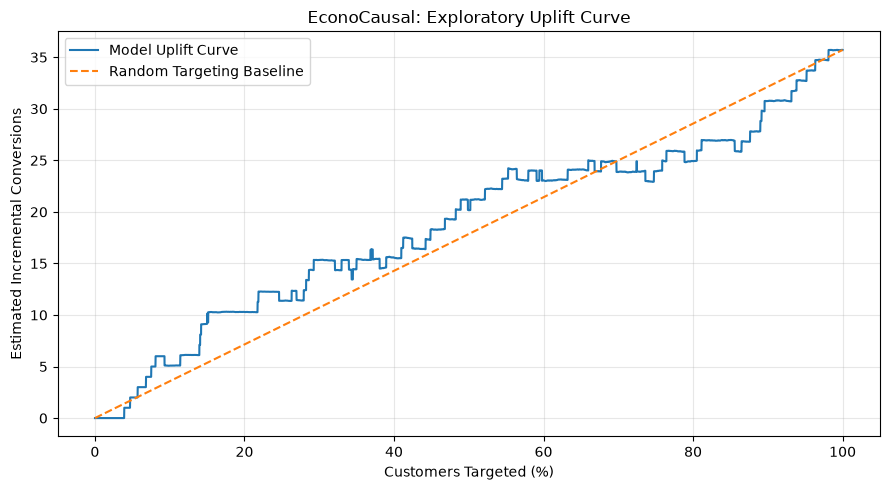

In [26]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    ranked["target_fraction"] * 100,
    ranked["uplift_curve"],
    label="Model Uplift Curve"
)

plt.plot(
    ranked["target_fraction"] * 100,
    ranked["random_baseline"],
    linestyle="--",
    label="Random Targeting Baseline"
)

plt.xlabel("Customers Targeted (%)")
plt.ylabel("Estimated Incremental Conversions")
plt.title("EconoCausal: Exploratory Uplift Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [27]:

# Step 11: Evaluate the top 20% of customers

top_20 = ranked[ranked["target_fraction"] <= 0.20].copy()

treat_n = (top_20["actual_treatment"] == 1).sum()
control_n = (top_20["actual_treatment"] == 0).sum()

treat_conversions = (
    top_20.loc[top_20["actual_treatment"] == 1, "actual_conversion"].sum()
)
control_conversions = (
    top_20.loc[top_20["actual_treatment"] == 0, "actual_conversion"].sum()
)

if treat_n > 0 and control_n > 0:
    email_rate = treat_conversions / treat_n
    control_rate = control_conversions / control_n

    print(f"Customers in top 20%: {len(top_20)}")
    print(f"Email group conversion rate: {email_rate:.3%}")
    print(f"Control group conversion rate: {control_rate:.3%}")
    print(f"Observed uplift: {(email_rate - control_rate) * 100:.3f} percentage points")
else:
    print("Not enough customers in both groups for comparison.")


Customers in top 20%: 1704
Email group conversion rate: 1.531%
Control group conversion rate: 0.217%
Observed uplift: 1.313 percentage points


In [28]:

# Step 12: Compare targeting strategies

targeting_results = []

for percentage in [20, 40, 60, 80, 100]:
    selected = ranked[
        ranked["target_fraction"] <= percentage / 100
    ]

    email = selected[selected["actual_treatment"] == 1]
    control = selected[selected["actual_treatment"] == 0]

    email_rate = email["actual_conversion"].mean()
    control_rate = control["actual_conversion"].mean()

    targeting_results.append({
        "Customers targeted (%)": percentage,
        "Customers": len(selected),
        "Email conversion (%)": email_rate * 100,
        "Control conversion (%)": control_rate * 100,
        "Observed uplift (pp)": (email_rate - control_rate) * 100
    })

targeting_comparison = pd.DataFrame(targeting_results)

display(targeting_comparison.round(3))


,Customers targeted (%),Customers,Email conversion (%),Control conversion (%),Observed uplift (pp)
0,20,1704,1.531,0.217,1.313
1,40,3409,1.511,0.570,0.940
2,60,5113,1.490,0.585,0.904
3,80,6818,1.318,0.588,0.731
4,100,8523,1.328,0.496,0.832


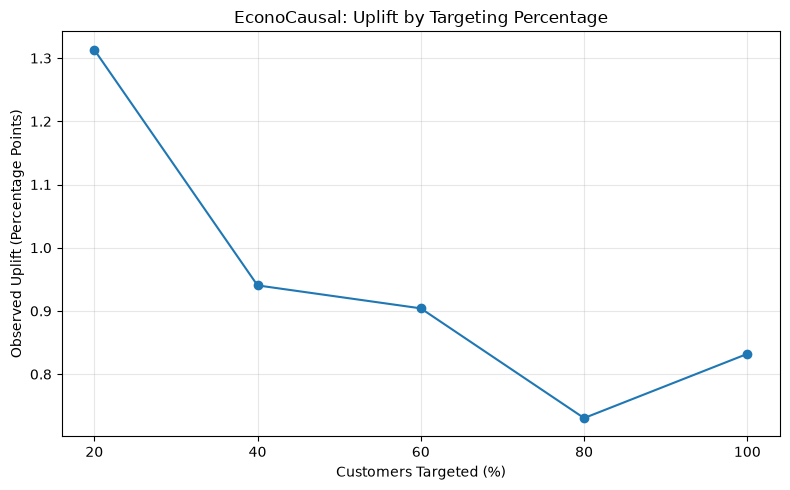

In [29]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    targeting_comparison["Customers targeted (%)"],
    targeting_comparison["Observed uplift (pp)"],
    marker="o"
)

plt.xlabel("Customers Targeted (%)")
plt.ylabel("Observed Uplift (Percentage Points)")
plt.title("EconoCausal: Uplift by Targeting Percentage")
plt.xticks([20, 40, 60, 80, 100])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [30]:

# Step 14: Analyse predicted customer uplift

positive = (uplift_results["estimated_uplift"] > 0).sum()
negative = (uplift_results["estimated_uplift"] < 0).sum()
zero = (uplift_results["estimated_uplift"] == 0).sum()

total = len(uplift_results)

print("PREDICTED CUSTOMER UPLIFT")
print("-" * 35)
print(f"Total test customers: {total:,}")
print(f"Predicted positive uplift: {positive:,} ({positive / total:.1%})")
print(f"Predicted negative uplift: {negative:,} ({negative / total:.1%})")
print(f"Predicted zero uplift: {zero:,} ({zero / total:.1%})")

print("\nMean predicted uplift:",
      f"{uplift_results['estimated_uplift'].mean() * 100:.3f} percentage points")


PREDICTED CUSTOMER UPLIFT
-----------------------------------
Total test customers: 8,523
Predicted positive uplift: 6,841 (80.3%)
Predicted negative uplift: 1,682 (19.7%)
Predicted zero uplift: 0 (0.0%)

Mean predicted uplift: 0.632 percentage points


In [31]:

# Step 15: Compare observed and predicted average uplift

email_test = uplift_results[
    uplift_results["actual_treatment"] == 1
]
control_test = uplift_results[
    uplift_results["actual_treatment"] == 0
]

observed_ate = (
    email_test["actual_conversion"].mean()
    - control_test["actual_conversion"].mean()
)

predicted_ate = uplift_results["estimated_uplift"].mean()

print("FINAL UPLIFT VALIDATION")
print("-" * 35)
print(f"Observed test-set ATE:  {observed_ate * 100:.3f} percentage points")
print(f"Predicted mean uplift:  {predicted_ate * 100:.3f} percentage points")
print(
    "Difference:             "
    f"{abs(observed_ate - predicted_ate) * 100:.3f} percentage points"
)


FINAL UPLIFT VALIDATION
-----------------------------------
Observed test-set ATE:  0.832 percentage points
Predicted mean uplift:  0.632 percentage points
Difference:             0.200 percentage points


In [32]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline

# Train separate models for treatment and control groups
hgb_treatment_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

hgb_control_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=43
    ))
])

# Fit using the same training groups as the Random Forest
hgb_treatment_model.fit(X_train_t, y_train_t)
hgb_control_model.fit(X_train_c, y_train_c)

print("HistGradientBoosting T-learner trained successfully.")

HistGradientBoosting T-learner trained successfully.


In [33]:
# Predict conversion probabilities for both potential treatments

hgb_prob_if_email = hgb_treatment_model.predict_proba(X_test)[:, 1]
hgb_prob_if_no_email = hgb_control_model.predict_proba(X_test)[:, 1]

# Calculate individual treatment effects
hgb_uplift = hgb_prob_if_email - hgb_prob_if_no_email

# Compare average predicted uplift
rf_mean_uplift = (
    prob_if_email - prob_if_no_email
).mean()

hgb_mean_uplift = hgb_uplift.mean()

print("MODEL COMPARISON")
print("-" * 40)
print(f"Random Forest mean uplift: {rf_mean_uplift * 100:.4f}%")
print(f"HistGradientBoosting mean uplift: {hgb_mean_uplift * 100:.4f}%")

MODEL COMPARISON
----------------------------------------
Random Forest mean uplift: 0.6323%
HistGradientBoosting mean uplift: 0.6300%


In [34]:
# Evaluate HistGradientBoosting uplift ranking

hgb_results = X_test.copy()
hgb_results["actual_treatment"] = t_test
hgb_results["actual_conversion"] = y_test
hgb_results["estimated_uplift"] = hgb_uplift

ranked_hgb = hgb_results.sort_values(
    "estimated_uplift", ascending=False
).copy()

is_t = (ranked_hgb["actual_treatment"] == 1).astype(int)
is_c = (ranked_hgb["actual_treatment"] == 0).astype(int)

cum_t_n = is_t.cumsum()
cum_c_n = is_c.cumsum()

cum_t_y = (ranked_hgb["actual_conversion"] * is_t).cumsum()
cum_c_y = (ranked_hgb["actual_conversion"] * is_c).cumsum()

control_adjustment = np.divide(
    cum_c_y * cum_t_n,
    cum_c_n,
    out=np.zeros(len(ranked_hgb), dtype=float),
    where=cum_c_n.to_numpy() > 0
)

hgb_curve = cum_t_y - control_adjustment

target_fraction = np.arange(
    1, len(ranked_hgb) + 1
) / len(ranked_hgb)

n_t = int(is_t.sum())
n_c = int(is_c.sum())

hgb_total_incremental = (
    cum_t_y.iloc[-1] - cum_c_y.iloc[-1] * n_t / n_c
)

hgb_baseline = target_fraction * hgb_total_incremental

x_hgb = np.concatenate(([0.0], target_fraction))
curve_hgb = np.concatenate(([0.0], hgb_curve.to_numpy()))
baseline_hgb = np.concatenate(([0.0], hgb_baseline))

hgb_qini = np.trapezoid(
    curve_hgb - baseline_hgb,
    x_hgb
)

print(f"HistGradientBoosting Qini: {hgb_qini:.4f}")
print(f"HistGradientBoosting incremental conversions: {hgb_total_incremental:.3f}")

HistGradientBoosting Qini: 2.3506
HistGradientBoosting incremental conversions: 35.707


In [35]:
# Compare observed uplift among the top 20% of customers

def evaluate_top_20(results, model_name):
    ranked = results.sort_values(
        "estimated_uplift", ascending=False
    )

    top_20 = ranked.head(int(np.ceil(len(ranked) * 0.20)))

    treatment_rate = top_20.loc[
        top_20["actual_treatment"] == 1,
        "actual_conversion"
    ].mean()

    control_rate = top_20.loc[
        top_20["actual_treatment"] == 0,
        "actual_conversion"
    ].mean()

    print(f"\n{model_name}")
    print(f"Treatment conversion: {treatment_rate * 100:.3f}%")
    print(f"Control conversion: {control_rate * 100:.3f}%")
    print(f"Observed uplift: {(treatment_rate - control_rate) * 100:.3f} percentage points")


evaluate_top_20(uplift_results, "Random Forest")
evaluate_top_20(hgb_results, "HistGradientBoosting")


Random Forest
Treatment conversion: 1.529%
Control conversion: 0.217%
Observed uplift: 1.311 percentage points

HistGradientBoosting
Treatment conversion: 1.771%
Control conversion: 0.466%
Observed uplift: 1.305 percentage points


In [36]:
def calculate_qini(results):
    ranked = results.sort_values(
        "estimated_uplift", ascending=False
    ).copy()

    treatment = (ranked["actual_treatment"] == 1).astype(int)
    control = (ranked["actual_treatment"] == 0).astype(int)

    cum_t_n = treatment.cumsum()
    cum_c_n = control.cumsum()

    cum_t_y = (
        ranked["actual_conversion"] * treatment
    ).cumsum()

    cum_c_y = (
        ranked["actual_conversion"] * control
    ).cumsum()

    if treatment.sum() == 0 or control.sum() == 0:
        raise ValueError("Both groups must be present.")

    adjustment = np.divide(
        cum_c_y * cum_t_n,
        cum_c_n,
        out=np.zeros(len(ranked), dtype=float),
        where=cum_c_n.to_numpy() > 0
    )

    curve = cum_t_y - adjustment

    x = np.arange(1, len(ranked) + 1) / len(ranked)

    total_incremental = (
        cum_t_y.iloc[-1]
        - cum_c_y.iloc[-1] * treatment.sum() / control.sum()
    )

    baseline = x * total_incremental

    x = np.concatenate(([0.0], x))
    curve = np.concatenate(([0.0], curve.to_numpy()))
    baseline = np.concatenate(([0.0], baseline))

    return np.trapezoid(curve - baseline, x)


rf_qini_check = calculate_qini(uplift_results)
hgb_qini_check = calculate_qini(hgb_results)

print("INDEPENDENT QINI VALIDATION")
print("Random Forest:", round(rf_qini_check, 4))
print("HistGradientBoosting:", round(hgb_qini_check, 4))
print("Test customers:", len(uplift_results), len(hgb_results))

INDEPENDENT QINI VALIDATION
Random Forest: 0.8665
HistGradientBoosting: 2.3506
Test customers: 8523 8523


In [37]:
import numpy as np

# Paired bootstrap comparison of Qini scores
rng = np.random.default_rng(42)

n_bootstrap = 1000
n = len(uplift_results)

qini_differences = []
rf_scores = []
hgb_scores = []

for _ in range(n_bootstrap):

    # Sample the same customer indices for both models
    indices = rng.integers(0, n, size=n)

    rf_sample = uplift_results.iloc[indices].copy()
    hgb_sample = hgb_results.iloc[indices].copy()

    # Skip samples missing either experimental group
    if rf_sample["actual_treatment"].nunique() < 2:
        continue

    rf_qini = calculate_qini(rf_sample)
    hgb_qini = calculate_qini(hgb_sample)

    rf_scores.append(rf_qini)
    hgb_scores.append(hgb_qini)
    qini_differences.append(hgb_qini - rf_qini)

# Calculate confidence intervals
rf_ci = np.percentile(rf_scores, [2.5, 97.5])
hgb_ci = np.percentile(hgb_scores, [2.5, 97.5])
difference_ci = np.percentile(qini_differences, [2.5, 97.5])

print("PAIRED BOOTSTRAP RESULTS")
print("Successful bootstrap samples:", len(qini_differences))

print(f"\nRandom Forest Qini: {np.mean(rf_scores):.4f}")
print(f"Random Forest 95% CI: [{rf_ci[0]:.4f}, {rf_ci[1]:.4f}]")

print(f"\nHistGradientBoosting Qini: {np.mean(hgb_scores):.4f}")
print(f"HistGradientBoosting 95% CI: [{hgb_ci[0]:.4f}, {hgb_ci[1]:.4f}]")

print(f"\nMean Qini difference (HGB - RF): {np.mean(qini_differences):.4f}")
print(
    f"Difference 95% CI: "
    f"[{difference_ci[0]:.4f}, {difference_ci[1]:.4f}]"
)

PAIRED BOOTSTRAP RESULTS
Successful bootstrap samples: 1000

Random Forest Qini: 0.8418
Random Forest 95% CI: [-3.6825, 5.0556]

HistGradientBoosting Qini: 2.3343
HistGradientBoosting 95% CI: [-2.7475, 7.7020]

Mean Qini difference (HGB - RF): 1.4925
Difference 95% CI: [-3.2586, 6.4940]



# EconoCausal — Progress Summary

## Work Completed
- Loaded and explored the Hillstrom email campaign dataset containing 64,000 customers.
- Checked data quality, missing values, customer characteristics, and campaign outcomes.
- Compared Men's Email, Women's Email, and No Email groups.
- Estimated the average treatment effect (ATE) and its 95% confidence interval.
- Built treatment and control Random Forest models to estimate customer-level uplift.
- Evaluated uplift groups, targeting percentages, and the exploratory Qini coefficient.
- Visualized campaign performance and compared observed versus predicted uplift.

## Key Results
- **Dataset size:** 64,000 customers, 12 original columns.
- **Men's Email conversion rate:** 1.253%.
- **No Email conversion rate:** 0.573%.
- **Estimated ATE:** +0.681 percentage points.
- **95% confidence interval:** +0.501 to +0.864 percentage points.
- **Test-set observed ATE:** +0.832 percentage points.
- **Mean predicted uplift:** +0.632 percentage points.
- **Exploratory Qini coefficient:** 0.8665.
- **Top 20% targeting group:** +1.313 percentage points observed uplift.

## Limitations and Next Steps
- Individual customer-level uplift predictions require further validation.
- The Qini result is exploratory and should not be treated as proof of model quality.
- The dataset studies email campaigns, not discount pricing.
- The Hillstrom email campaign analysis is complete. The discount-pricing component has been developed separately using synthetic pricing data. Further work focuses on reproducibility, validation, and integration of both components.


# Uplift Model Comparison and Validation

## 1. Objective

The objective was to compare the existing Random Forest T-learner with a HistGradientBoosting T-learner for estimating heterogeneous treatment effects in the Hillstrom randomized email experiment.

Both models used the same training and test split.

## 2. Models evaluated

**Random Forest T-learner (baseline)**
- Separate treatment and control models.
- 300 trees per model.
- Minimum samples per leaf: 20.
- No class weighting.

**HistGradientBoosting T-learner (alternative)**
- Separate treatment and control models.
- 200 boosting iterations.
- Learning rate: 0.05.
- Maximum leaf nodes: 15.
- L2 regularization: 1.0.

## 3. Model comparison results

| Metric | Random Forest | HistGradientBoosting |
|---|---:|---:|
| Mean predicted uplift | 0.6323% | 0.6300% |
| Qini coefficient | 0.8665 | 2.3506 |
| Top 20% treatment conversion | 1.529% | 1.771% |
| Top 20% control conversion | 0.217% | 0.466% |
| Top 20% observed uplift | 1.311 pp | 1.305 pp |

Both models estimated 35.707 incremental conversions in the held-out experiment.

The original Random Forest T-learner evaluation in Step 11 reported 1.313 percentage points. The 1.311 percentage-point result above comes from the separate model-comparison evaluation.

## 4. Bootstrap uncertainty analysis

A paired bootstrap with 1,000 successful resamples was used to assess uncertainty in the Qini comparison.

| Metric | Result |
|---|---:|
| Random Forest mean bootstrap Qini | 0.8418 |
| Random Forest 95% CI | [-3.6825, 5.0556] |
| HistGradientBoosting mean bootstrap Qini | 2.3343 |
| HistGradientBoosting 95% CI | [-2.7475, 7.7020] |
| Mean Qini difference (HGB − RF) | 1.4925 |
| Difference 95% CI | [-3.2586, 6.4940] |

The confidence interval for the Qini difference includes zero. Therefore, the observed difference does not establish a statistically clear advantage for HistGradientBoosting.

This bootstrap assesses uncertainty conditional on the fitted models and held-out test set. It does not capture variation from retraining the models.

## 5. Final conclusion

HistGradientBoosting achieved a higher Qini point estimate, while Random Forest achieved marginally higher observed uplift in the top 20% targeting group.

Because the bootstrap confidence interval for their Qini difference includes zero, there is insufficient evidence to conclude that HistGradientBoosting is superior.

The Random Forest T-learner is therefore retained as the baseline model. HistGradientBoosting is documented as an experimental alternative.

## 6. Limitations

- Qini is reported as an unnormalized area; its magnitude depends on the evaluation definition and sample size.
- Both models were evaluated on one held-out test split.
- Bootstrap uncertainty does not include model retraining variability.
- The Hillstrom dataset evaluates randomized email treatment, not real-world discount pricing.
- Individual customer treatment effects cannot be directly observed.

**Overall finding:** The alternative model provides a promising ranking result, but a reliable improvement over the existing baseline has not yet been demonstrated.